## Football clubs must decide how much to invest in player transfers while managing budgets and assessing player value. This project analyzes transfer records to understand how fees vary by player position, league, and transfer window, and how transfer fees compare with players’ market values.

### Business Questions
How do average transfer fees differ across player positions?
Which leagues have the highest average transfer fees?
Do transfer fees or fee-to-market-value ratios differ between Summer and Winter transfer windows?
Are transfer fees associated with player market value?
Is there a relationship between contract length and transfer fee?
Which clubs have the highest total transfer spending?

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("football_transfer.csv")

In [ ]:
df.head()

,player_id,player_name,age,country,position,from_club,to_club,from_league,to_league,transfer_fee_eur,...,contract_years,appearances,goal,assist,minutes_played,player_rating,season,transfer_window,transfer_type,transfer_id
0,P00001,Hugo Fernandez,20,England,Forward,Rio Ave,Al Taawoun,Primeira Liga,Saudi Pro League,40354439,...,2.0,25,12.0,2.0,2000,6.49,2025/26,Winter,Permanent,1
1,P00002,Marco King,32,France,Central Midfielder,Monza,Sevilla,Serie A,La Liga,4343595,...,2.0,9,1.0,1.0,544,6.13,2024/25,Summer,Loan,2
2,P00003,Oscar Garcia,23,Sweden,Winger,New York City FC,Internacional,MLS,Brasileirao,4313416,...,0.0,50,23.0,12.0,3431,7.57,2017/18,Summer,Loan,3
3,P00004,Aditya Wright,25,Belgium,Defensive Midfielder,Twente,Botafogo,Eredivisie,Brasileirao,16089719,...,6.0,32,3.0,5.0,1817,6.01,2025/26,Summer,Permanent,4
4,P00005,Leo Fernandez,27,Belgium,Centre-Back,Manchester City,LAFC,Premier League,MLS,32390804,...,6.0,19,2.0,0.0,1519,5.93,2019/20,Summer,Permanent,5


In [ ]:
df.shape

(50000, 21)

In [ ]:
df.columns

Index(['player_id', 'player_name', 'age', 'country', 'position', 'from_club',
       'to_club', 'from_league', 'to_league', 'transfer_fee_eur',
       'market_value_eur', 'contract_years', 'appearances', 'goal', 'assist',
       'minutes_played', 'player_rating', 'season', 'transfer_window',
       'transfer_type', 'transfer_id'],
      dtype='str')

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   player_id         50000 non-null  str    
 1   player_name       50000 non-null  str    
 2   age               50000 non-null  int64  
 3   country           49500 non-null  str    
 4   position          50000 non-null  str    
 5   from_club         50000 non-null  str    
 6   to_club           50000 non-null  str    
 7   from_league       50000 non-null  str    
 8   to_league         50000 non-null  str    
 9   transfer_fee_eur  50000 non-null  int64  
 10  market_value_eur  49600 non-null  float64
 11  contract_years    49700 non-null  float64
 12  appearances       50000 non-null  int64  
 13  goal              49500 non-null  float64
 14  assist            49500 non-null  float64
 15  minutes_played    50000 non-null  int64  
 16  player_rating     49400 non-null  float64
 17  seas

**Cleaning dataset**

In [ ]:
df.isnull().sum()

player_id             0
player_name           0
age                   0
country             500
position              0
from_club             0
to_club               0
from_league           0
to_league             0
transfer_fee_eur      0
market_value_eur    400
contract_years      300
appearances           0
goal                500
assist              500
minutes_played        0
player_rating       600
season                0
transfer_window       0
transfer_type         0
transfer_id           0
dtype: int64

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.dtypes

player_id               str
player_name             str
age                   int64
country                 str
position                str
from_club               str
to_club                 str
from_league             str
to_league               str
transfer_fee_eur      int64
market_value_eur    float64
contract_years      float64
appearances           int64
goal                float64
assist              float64
minutes_played        int64
player_rating       float64
season                  str
transfer_window         str
transfer_type           str
transfer_id           int64
dtype: object

In [ ]:
df.describe().round(2)

,age,transfer_fee_eur,market_value_eur,contract_years,appearances,goal,assist,minutes_played,player_rating,transfer_id
count,50000.00,5.000000e+04,4.960000e+04,49700.00,50000.00,49500.00,49500.00,50000.00,49400.00,50000.00
mean,23.89,2.843888e+07,4.229679e+07,3.09,25.00,4.31,3.37,1659.94,6.45,25000.50
std,4.26,3.110603e+07,2.384932e+07,1.87,9.93,4.08,3.07,739.98,0.52,14433.90
min,16.00,0.000000e+00,2.260666e+06,0.00,0.00,0.00,0.00,0.00,5.20,1.00
25%,21.00,5.003742e+06,2.523634e+07,2.00,18.00,1.00,1.00,1143.00,6.09,12500.75
50%,24.00,2.023754e+07,3.719837e+07,3.00,25.00,3.00,3.00,1606.00,6.44,25000.50
75%,27.00,3.982651e+07,5.369323e+07,5.00,32.00,6.00,5.00,2125.25,6.79,37500.25
max,41.00,2.200000e+08,1.800000e+08,6.00,55.00,35.00,24.00,4829.00,9.04,50000.00


In [ ]:
df.shape

(50000, 21)

In [ ]:
cols = [
    'market_value_eur',
    'contract_years',
    'goal',
    'assist',
    'player_rating'
]
for col in cols:
    df[col] = df[col].fillna(df[col].median())

In [ ]:
df.isnull().sum()

player_id             0
player_name           0
age                   0
country             500
position              0
from_club             0
to_club               0
from_league           0
to_league             0
transfer_fee_eur      0
market_value_eur      0
contract_years        0
appearances           0
goal                  0
assist                0
minutes_played        0
player_rating         0
season                0
transfer_window       0
transfer_type         0
transfer_id           0
dtype: int64

In [ ]:
df.isnull().sum()

player_id             0
player_name           0
age                   0
country             500
position              0
from_club             0
to_club               0
from_league           0
to_league             0
transfer_fee_eur      0
market_value_eur      0
contract_years        0
appearances           0
goal                  0
assist                0
minutes_played        0
player_rating         0
season                0
transfer_window       0
transfer_type         0
transfer_id           0
dtype: int64

In [ ]:
df['transfer_type'].value_counts()

transfer_type
Permanent        34867
Loan             11049
Free Transfer     4084
Name: count, dtype: int64

In [ ]:
df_permanent = df[df['transfer_type'] == 'Permanent'].copy()
print(df_permanent.shape)

(34867, 21)


In [ ]:
df_permanent['fee_to_mv'] = (df_permanent['transfer_fee_eur'] / df_permanent['market_value_eur'])

In [ ]:
df_permanent[['transfer_fee_eur', 'market_value_eur', 'fee_to_mv']].head()

,transfer_fee_eur,market_value_eur,fee_to_mv
0,40354439,41796383.0,0.965501
3,16089719,19490009.0,0.825537
4,32390804,24383874.0,1.328370
5,26498395,20264007.0,1.307658
6,16418195,19431506.0,0.844927


In [ ]:
df_permanent['fee_to_mv'].mean()

np.float64(0.9358860003083074)

In [ ]:
#How much money do clubs usually spend on football transfers

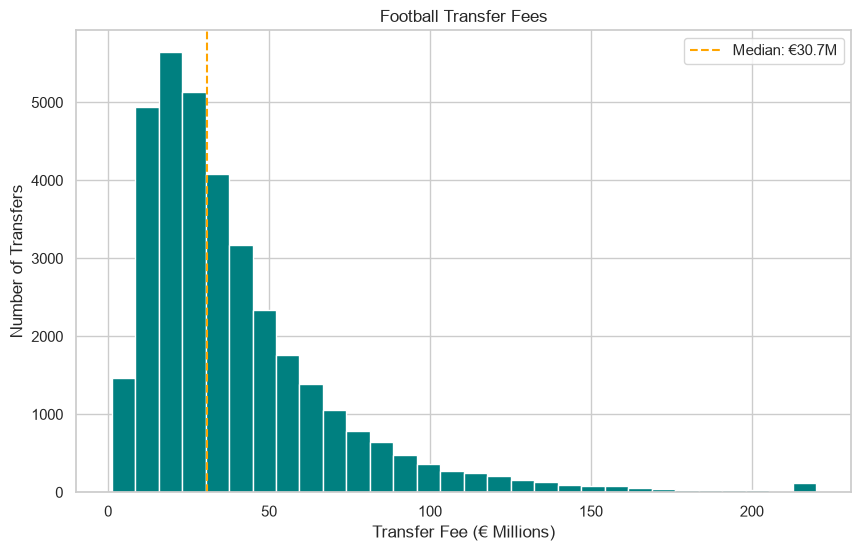

In [ ]:
# Convert fees to millions and remove missing values
fees = df_permanent["transfer_fee_eur"].dropna() / 1_000_000

# Draw the histogram
plt.figure(figsize=(10, 6))
plt.hist(fees, bins=30, color="teal", edgecolor="white")

# Show the median fee
median = fees.median()
plt.axvline(median, color="orange", linestyle="--",
            label=f"Median: €{median:.1f}M")

plt.title("Football Transfer Fees")
plt.xlabel("Transfer Fee (€ Millions)")
plt.ylabel("Number of Transfers")
plt.legend()
plt.show()

### Average Transfer fee by League

In [ ]:
league_fees = (df_permanent.groupby('to_league')['transfer_fee_eur'].mean() / 1_000_000).round(2)
print(league_fees.sort_values(ascending=False))

to_league
Premier League      52.56
La Liga             48.86
Bundesliga          44.18
Serie A             43.13
Ligue 1             35.73
Saudi Pro League    29.21
Primeira Liga       28.29
Eredivisie          25.75
Brasileirao         24.74
MLS                 24.17
Name: transfer_fee_eur, dtype: float64


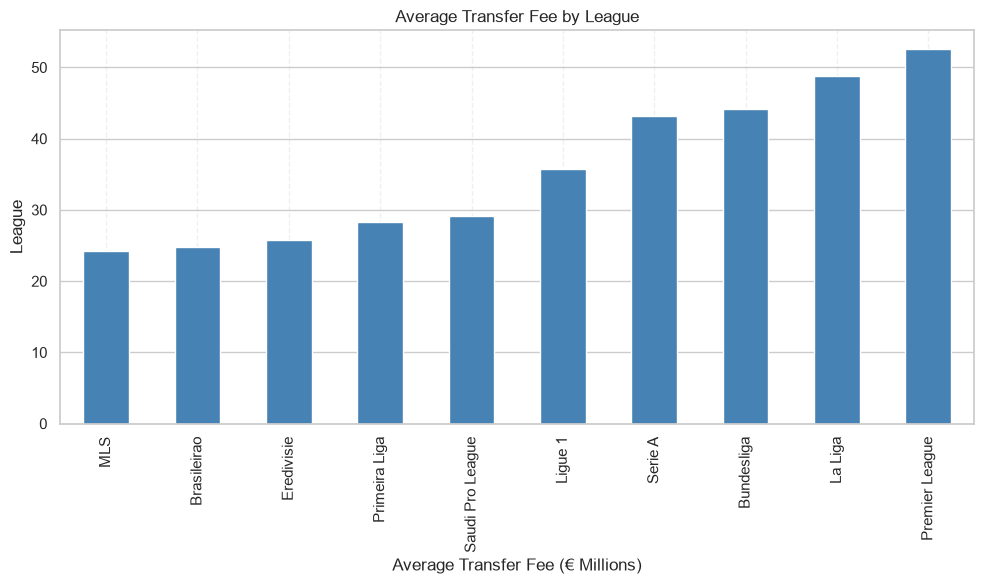

In [ ]:
ax = league_fees.sort_values().plot(
    kind="bar",
    figsize=(10, 6),
    color="steelblue"
)
ax.set_title("Average Transfer Fee by League")
ax.set_xlabel("Average Transfer Fee (€ Millions)")
ax.set_ylabel("League")
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Top 10 players by transfer

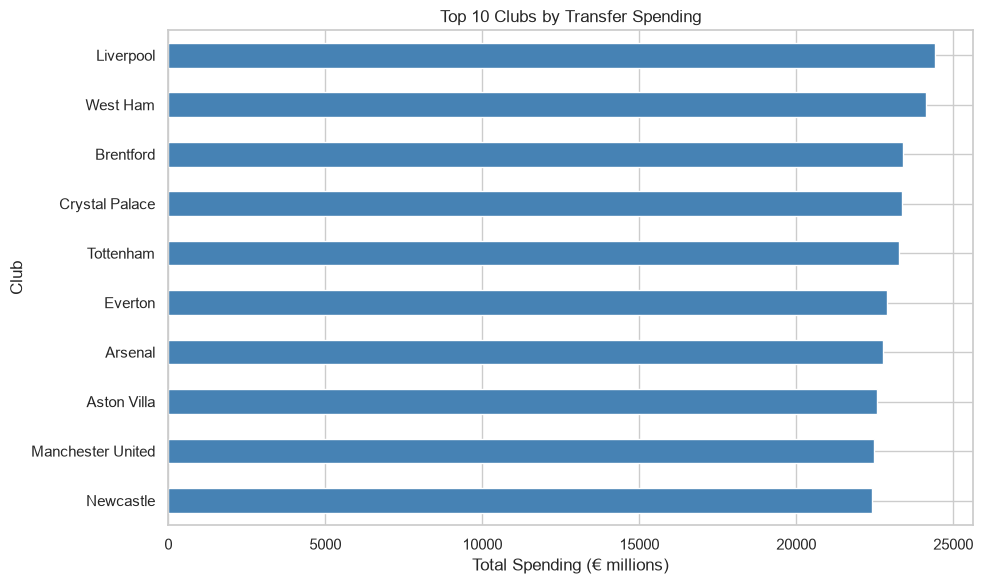

In [ ]:

# Find the 10 clubs with the highest total spending (in € millions)
top_spending = (df.dropna(subset=["to_club", "transfer_fee_eur"]).groupby("to_club")["transfer_fee_eur"].sum().nlargest(10).sort_values() / 1_000_000
)
# Draw a simple horizontal bar chart
top_spending.plot(kind="barh", figsize=(10, 6), color="steelblue")
plt.title("Top 10 Clubs by Transfer Spending")
plt.xlabel("Total Spending (€ millions)")
plt.ylabel("Club")
plt.tight_layout()
plt.show()


## Goals and Assists by Position

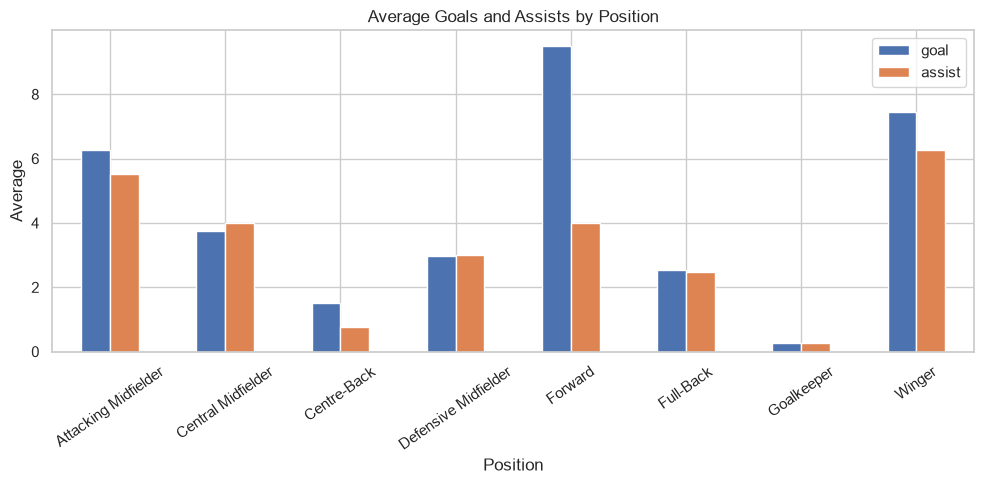

In [ ]:
# Calculate average goals and assists for each position
position_stats = df.groupby("position")[["goal", "assist"]].mean()

# Plot the averages as grouped bars
position_stats.plot(kind="bar", figsize=(10, 5))
plt.title("Average Goals and Assists by Position")
plt.xlabel("Position")
plt.ylabel("Average")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

## Transfer by Season and Window

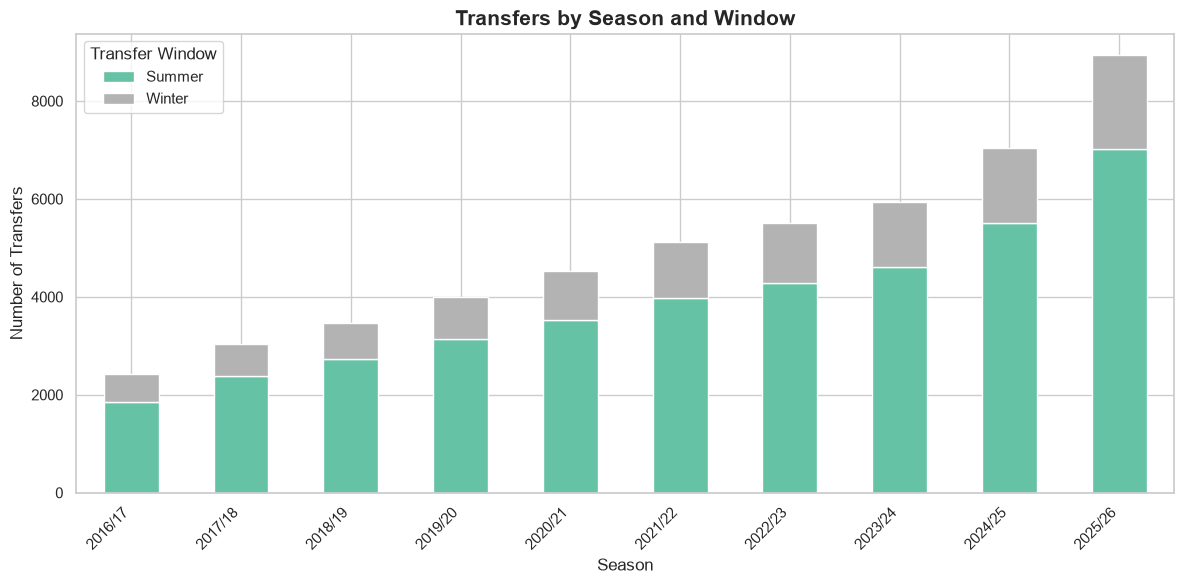

In [ ]:
# Count transfers by season and transfer window
season_window = pd.crosstab(df["season"], df["transfer_window"]).sort_index()

# Draw a stacked bar chart
ax = season_window.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="Set2"
)
ax.set_title("Transfers by Season and Window", fontsize=15, weight="bold")
ax.set_xlabel("Season")
ax.set_ylabel("Number of Transfers")
ax.legend(title="Transfer Window")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Average Transfer Fee By Position

In [ ]:
position_fees = (df_permanent.groupby('position')['transfer_fee_eur'].mean() / 1_000_000).round(2)
print(position_fees.sort_values(ascending=False))

position
Winger                  44.38
Forward                 44.13
Attacking Midfielder    44.05
Central Midfielder      40.27
Defensive Midfielder    37.73
Full-Back               37.28
Centre-Back             33.99
Goalkeeper              33.20
Name: transfer_fee_eur, dtype: float64


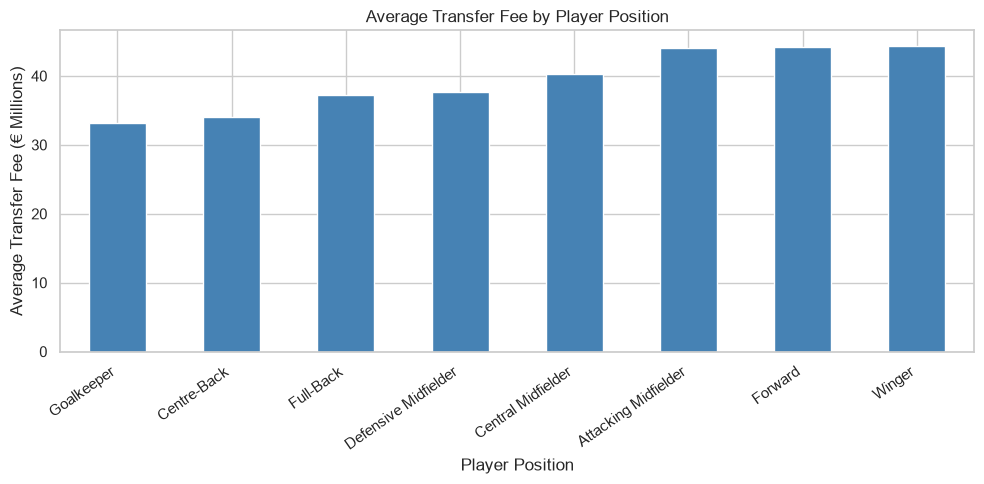

In [ ]:
# Sort average transfer fees
fees = position_fees.sort_values()

# Draw a bar chart
fees.plot(kind="bar", figsize=(10, 5), color="steelblue")

plt.title("Average Transfer Fee by Player Position")
plt.xlabel("Player Position")
plt.ylabel("Average Transfer Fee (€ Millions)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Hypothesis Testing:

### Objective: To check whether average transfer fees differ across player positions.

### Null Hypothesis (H0): The average transfer fees are equal across all player positions.

### Alternative Hypothesis (H1): At least one player position has a different average transfer fee.

## Perform One-Way ANOVA test

In [ ]:
from scipy.stats import f_oneway
groups = [group['transfer_fee_eur'].dropna()for _, group in df_permanent.groupby('position')]
f_stat, p_value = f_oneway(*groups)
print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 86.53854615913872
P-value: 1.7998456430986497e-125


### Result: Since p-value < 0.05, we reject H0.
### Conclusion: Average transfer fees differ significantly across player positions.

### The ANOVA test showed a statistically significant difference in average transfer fees across player positions (F = 86.54, p < 0.05). This suggests that player position is associated with transfer fee differences.

# Graph

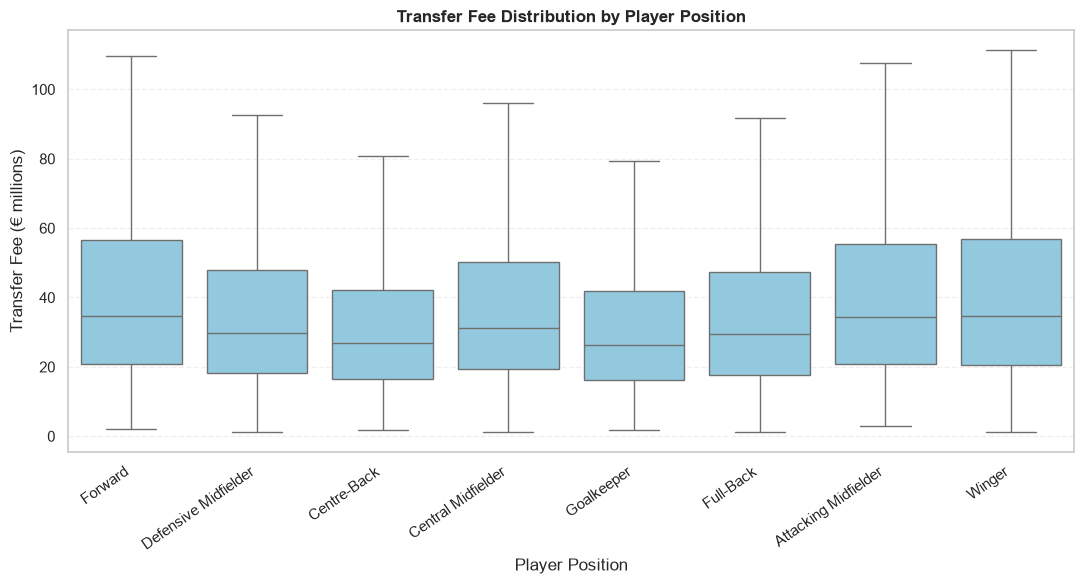

In [ ]:
# Show the transfer-fee distribution for each position (in € millions)
plt.figure(figsize=(11, 6))
sns.boxplot(
    data=df_permanent.dropna(subset=["position", "transfer_fee_eur"]),
    x="position",
    y=df_permanent["transfer_fee_eur"] / 1_000_000,
    color="skyblue",
    showfliers=False
)
plt.title("Transfer Fee Distribution by Player Position", weight="bold")
plt.xlabel("Player Position")
plt.ylabel("Transfer Fee (€ millions)")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

### Insight: Transfer fees vary across player positions. The ANOVA test found a significant difference between positions (p < 0.05), so we reject the null hypothesis. At least one position has a different average fee.



# Hypothesis Testing 2 - Two sample t test
### Objective: Compare the fee-to-market-value ratio
### between Summer and Winter transfer windows.

### H0: The average fee-to-market-value ratio is equal in Summer and Winter.

### H1: The average fee-to-market-value ratio is different between Summer and Winter.

In [ ]:
from scipy.stats import ttest_ind

# Filter Summer and Winter transfer windows, drop NaNs
summer = df_permanent[df_permanent['transfer_window'] == 'Summer']['fee_to_mv'].dropna()
winter = df_permanent[df_permanent['transfer_window'] == 'Winter']['fee_to_mv'].dropna()

# Perform independent t-test (equal variances assumed by default)
t_stat, p_value = ttest_ind(summer, winter, equal_var=False)

print("Summer average:", summer.mean().round(2))
print("Winter average:", winter.mean().round(2))
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

# Interpretation
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: Means are significantly different.")
else:
    print("Fail to reject the null hypothesis: No significant difference in means.")


Summer average: 0.93
Winter average: 0.94
T-statistic: -1.3162
P-value: 0.1881
Fail to reject the null hypothesis: No significant difference in means.


### Conclusion
The average fee-to-market-value ratios were 0.93 for Summer transfers and 0.94 for Winter transfers. Welch’s t-test found no statistically significant difference between them (t = -1.3162, p = 0.1881). Since p > 0.05, we fail to reject the null hypothesis. There is not enough evidence that the average ratios differ by transfer window.

# Graph

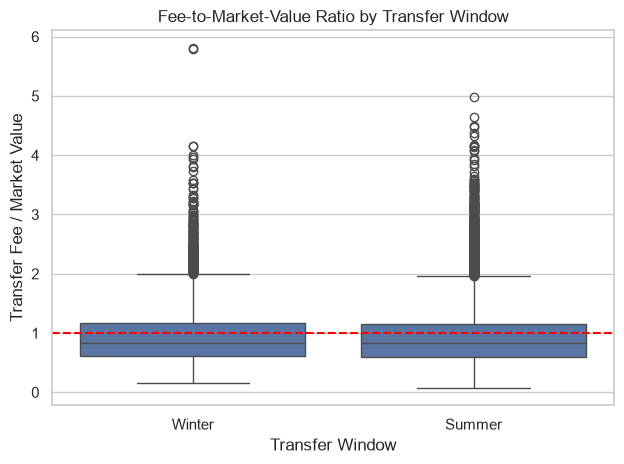

In [ ]:
# Keep rows with a transfer window and ratio
window_data = df_permanent.dropna(subset=["transfer_window", "fee_to_mv"])

# Compare ratios for Summer and Winter transfers
sns.boxplot(data=window_data, x="transfer_window", y="fee_to_mv")

# Add a reference line for a fee equal to market value
plt.axhline(1, color="red", linestyle="--")
plt.title("Fee-to-Market-Value Ratio by Transfer Window")
plt.xlabel("Transfer Window")
plt.ylabel("Transfer Fee / Market Value")
plt.tight_layout()
plt.show()

### Insight: Summer and Winter ratios look similar. The t-test found no statistically significant difference (p = 0.1812), so we do not have enough evidence that the average ratio differs by transfer window.



# 3) One-Sample t-Test
### Are clubs paying above market value?

### To check whether the average transfer fee is significantly different from the player's market value.

### We use a one-sample t-test because we want to compare the average fee_to_mv ratio with a fixed value of 1.
- Ratio = 1: Transfer fee equals market value.
- Ratio > 1: Transfer fee is above market value.
- Ratio < 1: Transfer fee is below market value.

## Hypothesis
- Null hypothesis (H₀): The average fee-to-market-value ratio is equal to 1.
- Alternative hypothesis (H₁): The average fee-to-market-value ratio is different from 1.

In [ ]:
from scipy.stats import ttest_1samp

# H0: Average fee-to-market-value ratio = 1
# H1: Average fee-to-market-value ratio != 1

ratios = df_permanent['fee_to_mv'].dropna()
t_stat, p_value = ttest_1samp(ratios, popmean=1)
print("Average ratio:", ratios.mean().round(2))
print("T-statistic:", t_stat.round(2))
print("P-value:", p_value)

Average ratio: 0.94
T-statistic: -25.27
P-value: 1.242664858092323e-139


### Result: Compare the p-value with 0.05.
### Conclusion: If p-value < 0.05, reject H0.
### The average fee-to-market-value ratio is significantly different from 1.

# Graph

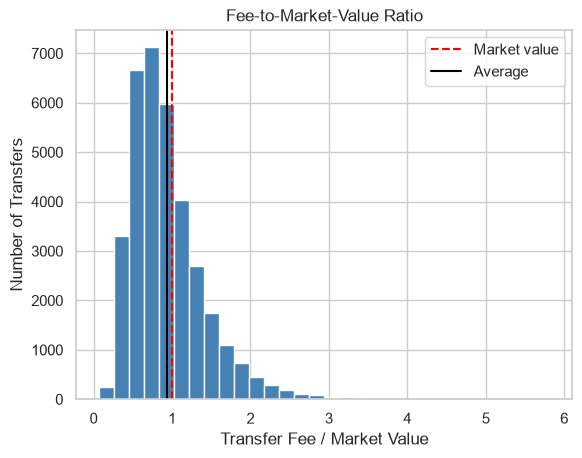

In [ ]:
ratios = df_permanent["fee_to_mv"].dropna()

plt.hist(ratios, bins=30, color="steelblue")
plt.axvline(1, color="red", linestyle="--", label="Market value")
plt.axvline(ratios.mean(), color="black", label="Average")

plt.title("Fee-to-Market-Value Ratio")
plt.xlabel("Transfer Fee / Market Value")
plt.ylabel("Number of Transfers")
plt.legend()
plt.show()

### Insight: The average ratio is about 0.94, below 1. The test found this difference statistically significant (p < 0.05), suggesting that permanent transfers cost less than market value on average.



### Check the relationship between contract years and transfer fees

#### H₀ (Null hypothesis): There is no linear relationship between contract years and transfer fees.

#### H₁ (Alternative hypothesis): There is a linear relationship between contract years and transfer fees.

In [ ]:
from scipy.stats import pearsonr
# Remove rows with missing values in either column
data = df_permanent[
    ['contract_years', 'transfer_fee_eur']
].dropna()
# Perform Pearson correlation test
r, p_value = pearsonr(
    data['contract_years'],
    data['transfer_fee_eur']
)
print("Correlation coefficient:", r)
print("P-value:", p_value)

Correlation coefficient: -0.003877040373512363
P-value: 0.46911167702691914


### Conclusion
## The correlation is almost zero (r = -0.004), and the p-value is 0.469. Since the p-value is greater than 0.05, there is not enough evidence of a linear relationship between contract length and transfer fee.

## Identify Factors Affecting Transfer Fees

### Objective: Check whether a player's age is related to their transfer fee.


# Visualize Transfer Fees vs Market Values

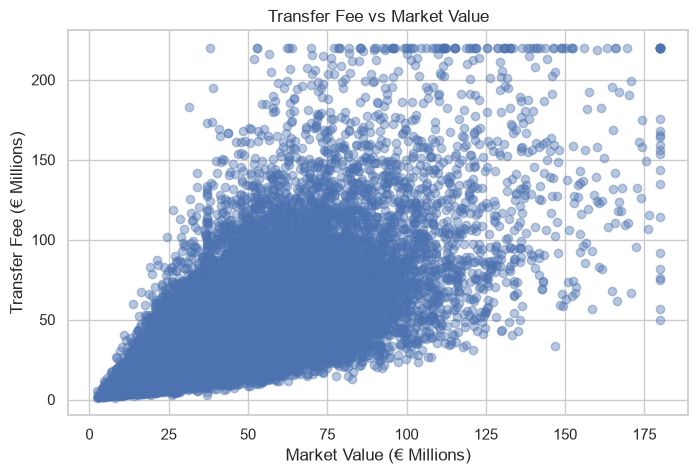

In [ ]:
# Objective: Visualize the relationship between transfer fees and market values.
plt.figure(figsize=(8, 5))
plt.scatter(df_permanent['market_value_eur'] / 1_000_000,df_permanent['transfer_fee_eur'] / 1_000_000,alpha=0.4)
plt.xlabel("Market Value (€ Millions)")
plt.ylabel("Transfer Fee (€ Millions)")
plt.title("Transfer Fee vs Market Value")

plt.show()

## Conclusion:
### The scatter plot shows a positive relationship between market value and transfer fee. However, transfer fees vary considerably for players with similar market values, suggesting that other factors may also influence transfer fees.

## Objective: Find the percentage of permanent transfers
### where the transfer fee is above the player's market value.

In [ ]:
above_market = (df_permanent['transfer_fee_eur'] > df_permanent['market_value_eur']).sum()
total_transfers = len(df_permanent)
percentage = (above_market / total_transfers) * 100
print("Transfers above market value:", above_market)
print("Total permanent transfers:", total_transfers)
print("Percentage above market value:", round(percentage, 2), "%")

Transfers above market value: 12245
Total permanent transfers: 34867
Percentage above market value: 35.12 %


## Objective: Find the 10 most expensive permanent transfers.


In [ ]:
top_10 = df_permanent.sort_values(by='transfer_fee_eur', ascending=False).head(10)
print(top_10[
    [ 'player_name','age', 'position',
     'from_club', 'to_club',
     'transfer_fee_eur', 'market_value_eur']
])

             player_name  age              position         from_club  \
34516  Cristiano Ronaldo   22             Full-Back          Al Nassr   
16838          Max Allen   23             Full-Back          Atalanta   
23987    Elias Fernandez   27    Central Midfielder          Valencia   
42916      Ethan Schmidt   19  Attacking Midfielder          Sassuolo   
7145       Ethan Schmidt   24               Forward         Groningen   
16819     Oscar Anderson   28  Defensive Midfielder              Nice   
11827       Oliver Rossi   26                Winger     Athletic Club   
27152        Ivan Wilson   26                Winger  Bayer Leverkusen   
28354     Oscar Anderson   24    Central Midfielder         Tottenham   
38147     Lucas Martinez   23             Full-Back           Estoril   

                        to_club  transfer_fee_eur  market_value_eur  
34516                   Chelsea         220000000        81934673.0  
16838  Borussia Monchengladbach         220000000       

In [ ]:
print("Shape:", top_10.shape)

print(top_10[['player_name', 'transfer_fee_eur', 'market_value_eur']])

Shape: (10, 22)
             player_name  transfer_fee_eur  market_value_eur
34516  Cristiano Ronaldo         220000000        81934673.0
16838          Max Allen         220000000       140935312.0
23987    Elias Fernandez         220000000       101052772.0
42916      Ethan Schmidt         220000000       122006036.0
7145       Ethan Schmidt         220000000       110160445.0
16819     Oscar Anderson         220000000       101660988.0
11827       Oliver Rossi         220000000       142029563.0
27152        Ivan Wilson         220000000        78689330.0
28354     Oscar Anderson         220000000        77064362.0
38147     Lucas Martinez         220000000       180000000.0


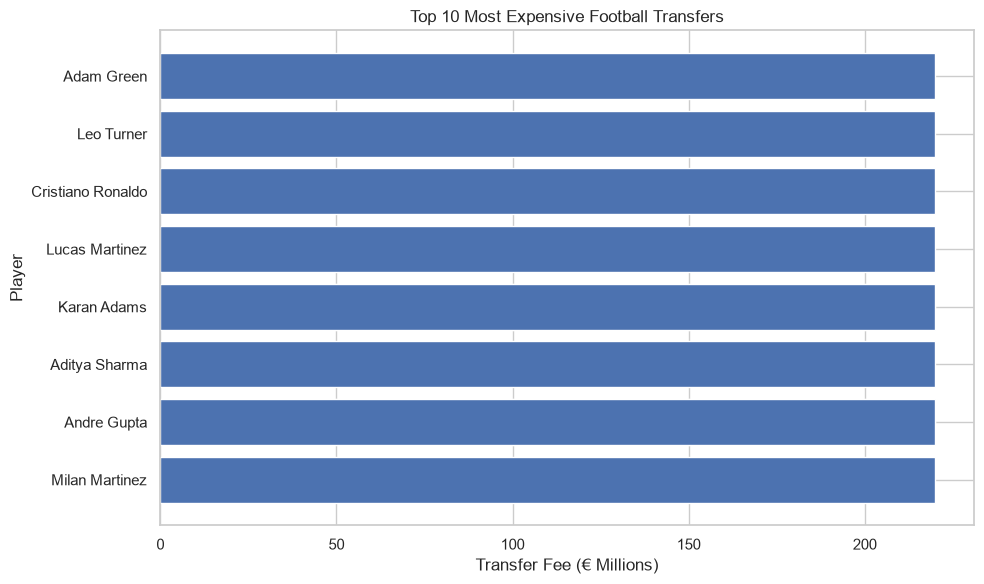

In [ ]:
# Get the 10 most expensive permanent transfers
top_10 = df_permanent.nlargest(10, 'transfer_fee_eur').copy()

# Create labels using player names, or player IDs if names are missing
top_10['label'] = top_10['player_name'].fillna(
    top_10['player_id'].astype(str)
)

# Sort for horizontal bar chart
top_10_sorted = top_10.sort_values('transfer_fee_eur')

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_sorted['label'].astype(str),
    top_10_sorted['transfer_fee_eur'] / 1_000_000
)

plt.xlabel("Transfer Fee (€ Millions)")
plt.ylabel("Player")
plt.title("Top 10 Most Expensive Football Transfers")
plt.tight_layout()
plt.show()

## Conclusion:
### The bar chart displays the 10 most expensive permanent transfers.
### The selected transfers have fees close to €220 million.
### Missing player names are represented by player IDs.


## Business Insights and Conclusion

1. Average transfer fees differed across player positions (ANOVA p < 0.05). This shows an association between position and transfer fees; it does not prove that position causes the difference.

2. The average fee-to-market-value ratio was about 0.94. The one-sample test found it significantly different from 1 (p < 0.05), meaning fees in this dataset averaged below the recorded market values.

3. The average fee-to-market-value ratios were not significantly different between Summer and Winter transfers (p = 0.181). This analysis does not show a clear difference between the two windows.

4. Contract years and transfer fees had almost no linear correlation (r = -0.004, p = 0.469). There is not enough evidence of a linear relationship between them.

5. The chart suggests that transfer fees tend to rise with market value, but the chart alone does not prove that market value causes higher fees.

## Recommendations

- Clubs can use market value as one reference point when reviewing transfer fees, while considering other player and deal factors.
- Compare transfer fees across positions and leagues as part of budgeting, but do not treat these patterns as proof of cause and effect.
- Collect verified, complete data and test relationships further before making transfer decisions.